# Módulo 1 — Fundamentos, Espacios de Color y Mejoramiento Digital
**PupilTrack — PSIB, ITBA (2do Q 2026)**

Para usarlo con un video propio: cambiar solo `VIDEO_PATH` en la celda de abajo.
Sin video, usa una imagen sintética de ojo para validar el flujo.

In [3]:
VIDEO_PATH = ""          # ej: "registro_A_1.mp4"
ROI_MANUAL = None        # ej: (x, y, w, h)
FRAME_INDICE = None

## Setup

In [4]:
import sys, os
sys.path.append(os.path.abspath(".."))

import cv2
import numpy as np
import matplotlib.pyplot as plt

from pupiltrack import acquisition as acq
from pupiltrack import preprocessing as pp
from pupiltrack import filtering as filt
from pupiltrack import edges_frequency as ef

plt.rcParams["figure.figsize"] = (5, 5)

def mostrar(img, titulo="", cmap="gray"):
    plt.figure()
    plt.imshow(img, cmap=cmap)
    plt.title(titulo)
    plt.axis("off")
    plt.show()

## Carga del frame de trabajo

No se encontró VIDEO_PATH: usando imagen sintética de prueba.


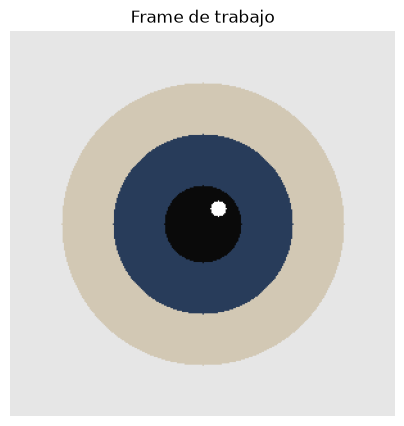

In [5]:
def generar_ojo_sintetico(size=300):
    img = np.full((size, size, 3), 230, dtype=np.uint8)
    centro = (size // 2, size // 2)
    cv2.circle(img, centro, 110, (180, 200, 210), -1)
    cv2.circle(img, centro, 70, (90, 60, 40), -1)
    cv2.circle(img, centro, 30, (10, 10, 10), -1)
    cv2.circle(img, (centro[0] + 12, centro[1] - 12), 6, (255, 255, 255), -1)
    return img

if VIDEO_PATH and os.path.exists(VIDEO_PATH):
    frames, fps = acq.extraer_frames(VIDEO_PATH)
    frame_completo = acq.frame_representativo(frames, FRAME_INDICE)
    if ROI_MANUAL is not None:
        x, y, w, h = ROI_MANUAL
        frame = frame_completo[y:y+h, x:x+w]
    else:
        frame, roi = acq.seleccionar_roi(frame_completo)
        print("ROI seleccionada:", roi)
    print(f"Video cargado: {VIDEO_PATH} | fps={fps:.1f} | frames={len(frames)}")
else:
    frame = generar_ojo_sintetico()
    print("No se encontró VIDEO_PATH: usando imagen sintética de prueba.")

mostrar(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), "Frame de trabajo")

## 1.1 — Carga, muestreo y espacios de color

In [6]:
info = pp.info_imagen(frame)

Dimensiones: 300x300 | Canales: 3 | Profundidad: uint8


**Submuestreo:**

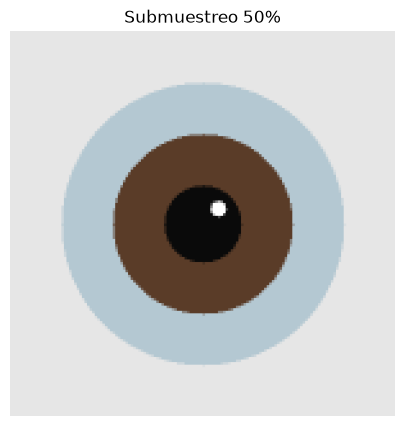

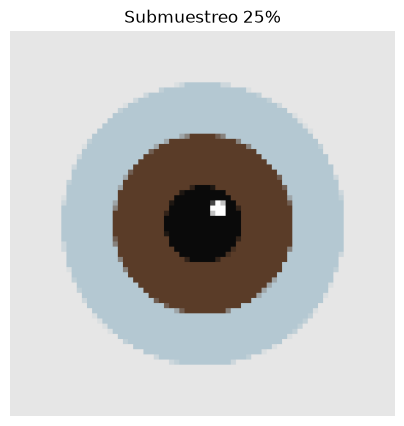

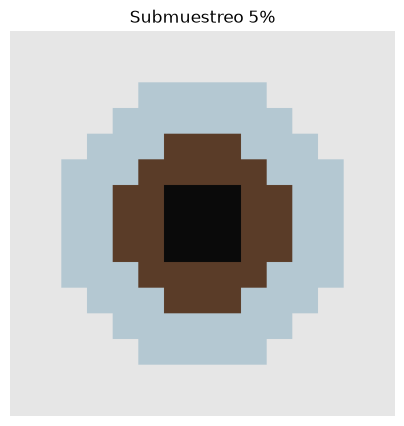

In [7]:
for pct in [0.5, 0.25, 0.05]:
    mostrar(pp.submuestrear(frame, pct), f"Submuestreo {int(pct*100)}%")

**Cuantización:**

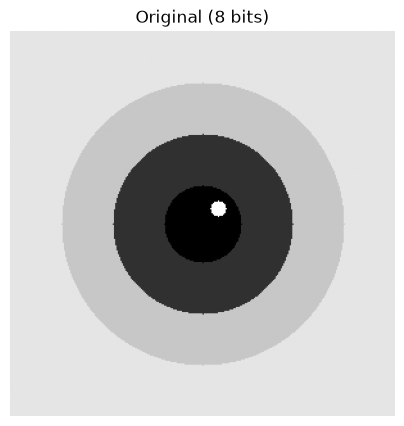

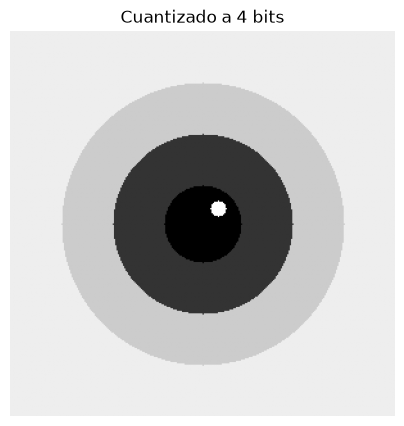

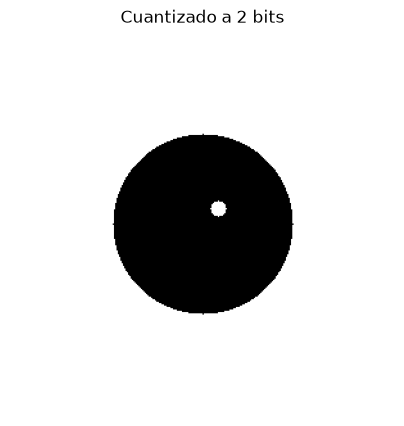

In [8]:
gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
mostrar(gris, "Original (8 bits)")
for bits in [4, 2]:
    mostrar(pp.cuantizar(gris, bits), f"Cuantizado a {bits} bits")

**Canales RGB y HSV:**

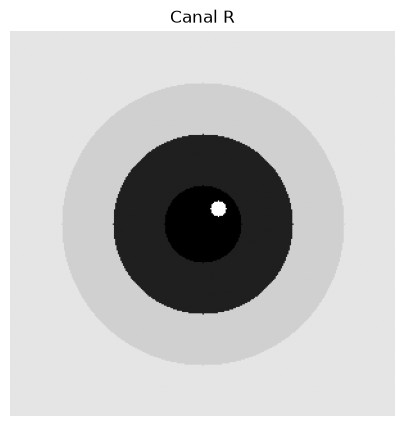

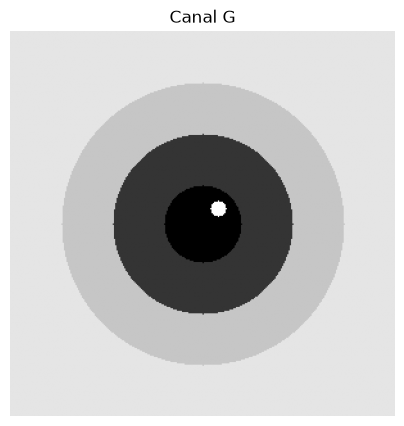

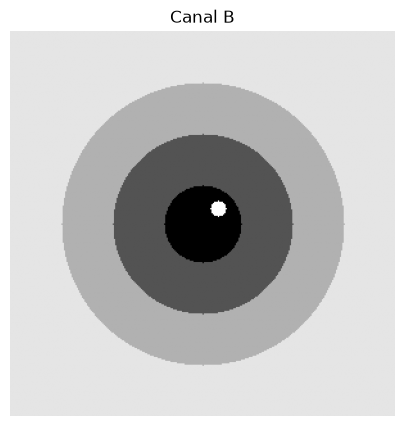

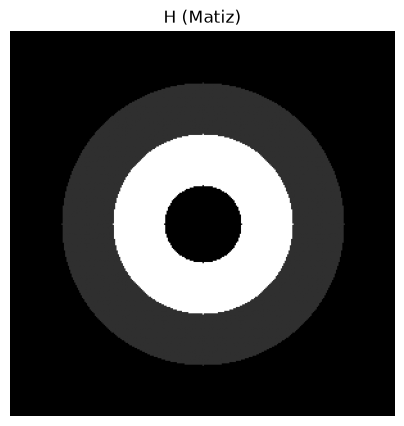

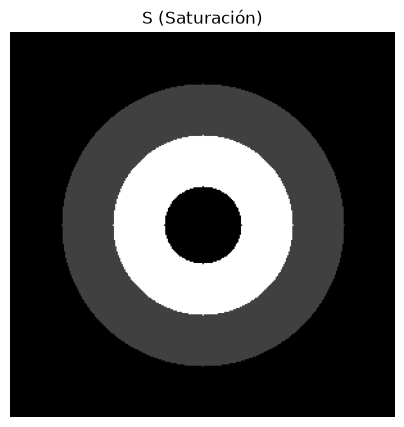

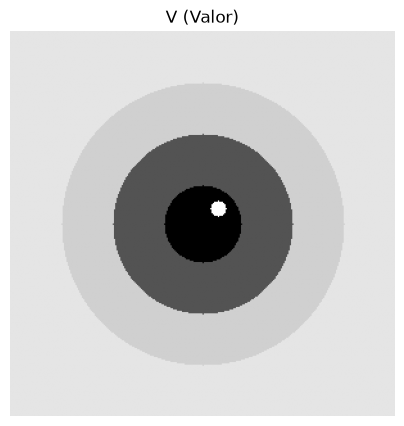

In [9]:
r, g, b = pp.separar_canales_rgb(frame)
mostrar(r, "Canal R"); mostrar(g, "Canal G"); mostrar(b, "Canal B")

h, s, v = pp.rgb_a_hsv(frame)
mostrar(h, "H (Matiz)"); mostrar(s, "S (Saturación)"); mostrar(v, "V (Valor)")

## 1.2 — Histograma, brillo/contraste, filtrado espacial

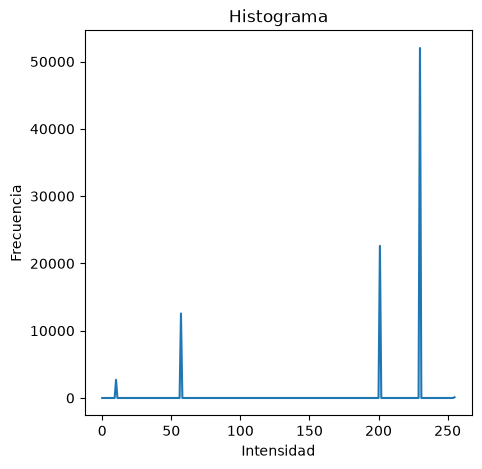

In [10]:
hist = pp.histograma_gris(gris)
plt.figure(); plt.plot(hist)
plt.title("Histograma"); plt.xlabel("Intensidad"); plt.ylabel("Frecuencia")
plt.show()

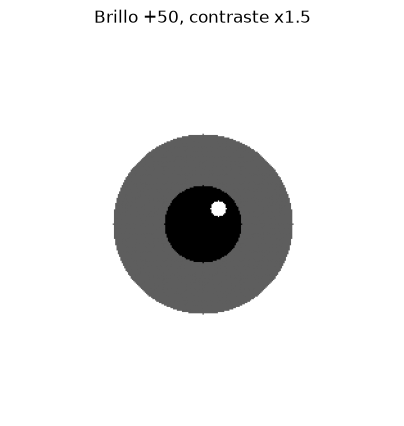

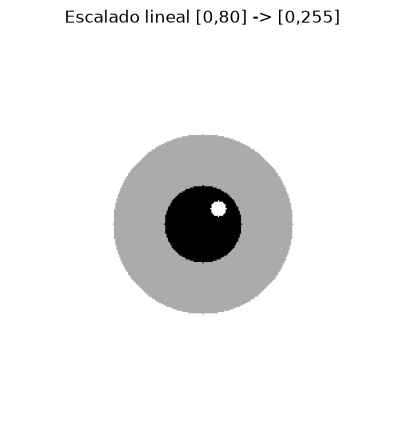

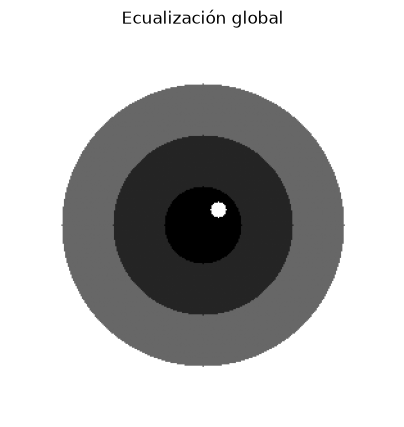

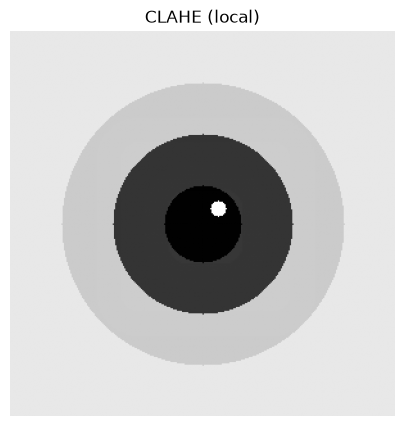

In [11]:
mostrar(pp.ajustar_brillo_contraste(gris, brillo=50, contraste=1.5), "Brillo +50, contraste x1.5")
mostrar(pp.escalado_por_rango(gris, 0, 80), "Escalado lineal [0,80] -> [0,255]")
mostrar(pp.ecualizar_histograma(gris, "global"), "Ecualización global")
mostrar(pp.ecualizar_histograma(gris, "clahe"), "CLAHE (local)")

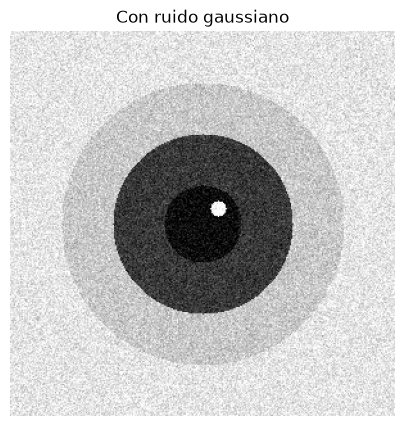

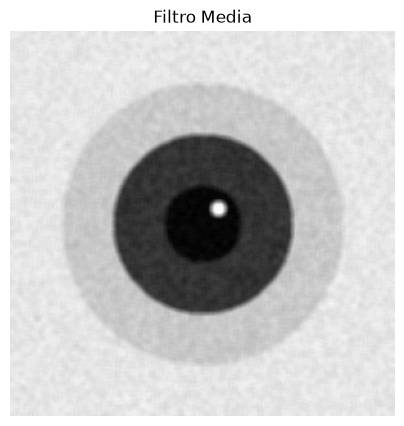

Media      PSNR=29.61 dB   SSIM=0.8303


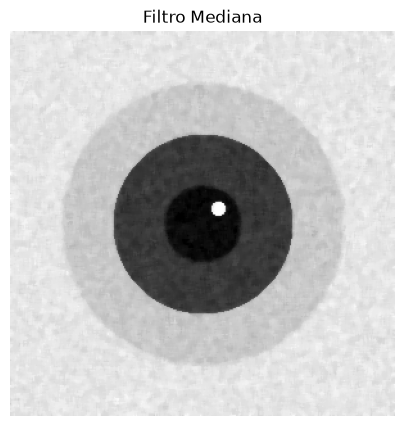

Mediana    PSNR=31.86 dB   SSIM=0.7715


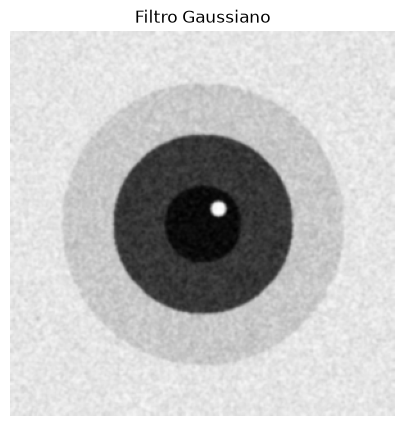

Gaussiano  PSNR=30.17 dB   SSIM=0.7203


In [12]:
ruidosa = filt.agregar_ruido_gaussiano(gris, sigma=20)
mostrar(ruidosa, "Con ruido gaussiano")
for nombre, filtrada in [
    ("Media", filt.filtro_media(ruidosa)),
    ("Mediana", filt.filtro_mediana(ruidosa)),
    ("Gaussiano", filt.filtro_gaussiano(ruidosa)),
]:
    mostrar(filtrada, f"Filtro {nombre}")
    print(f"{nombre:10s} PSNR={filt.psnr(gris, filtrada):.2f} dB   SSIM={filt.ssim(gris, filtrada):.4f}")

**Pregunta de la guía:** ¿qué filtro preserva mejor los bordes de la pupila eliminando destellos? _(completar con la comparación de arriba)_

## 1.3 — Bordes y dominio frecuencial

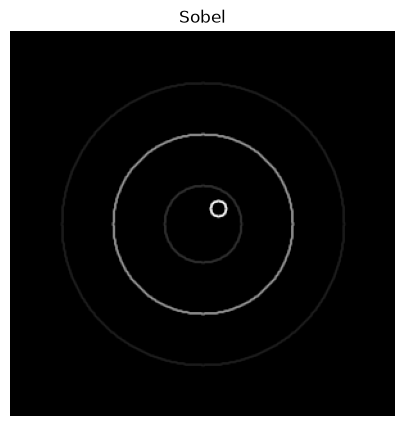

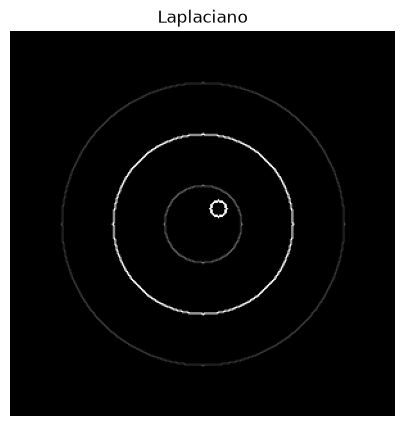

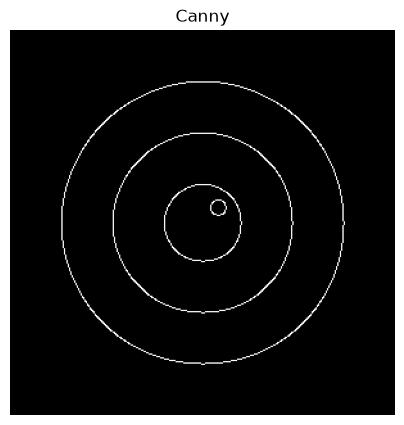

In [13]:
mostrar(ef.bordes_sobel(gris), "Sobel")
mostrar(ef.bordes_laplaciano(gris), "Laplaciano")
mostrar(ef.bordes_canny(gris), "Canny")

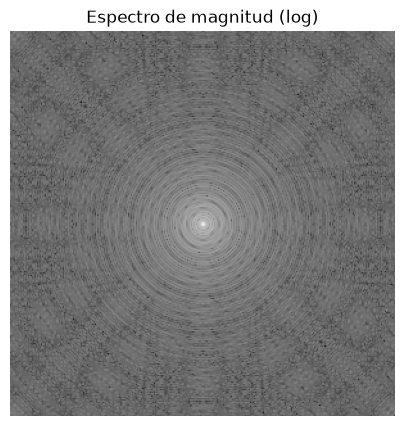

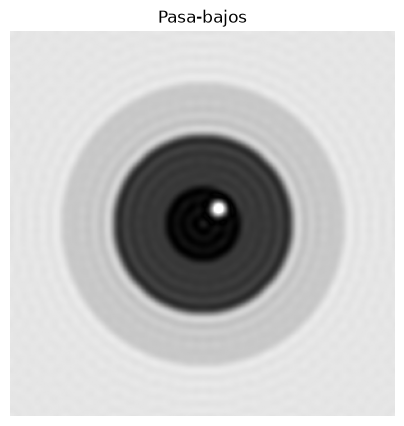

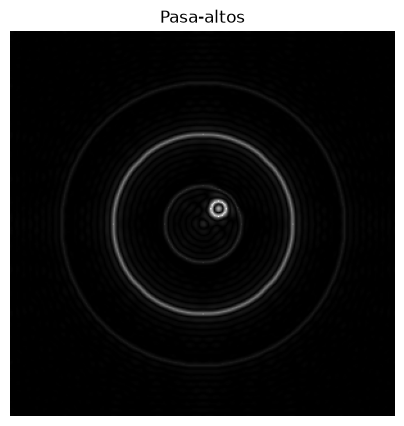

In [14]:
fft_shift = ef.fft2d(gris)
mostrar(ef.espectro_magnitud(fft_shift), "Espectro de magnitud (log)")
mostrar(ef.filtro_frecuencial(gris, "pasabajos", radio=30), "Pasa-bajos")
mostrar(ef.filtro_frecuencial(gris, "pasaaltos", radio=30), "Pasa-altos")

**Pregunta de la guía:** ¿cómo cuantificar la calidad de una imagen respecto a la original? PSNR/SSIM ya calculados arriba.